# 09 · Causal discovery with the PC algorithm

Notebooks 01–08 *assumed* a causal graph and estimated effects. Causal discovery tries to **learn the graph**
from data, using conditional independence:

- A chain `X → Z → Y` and a fork `X ← Z → Y` both imply $X \perp Y \mid Z$, so they can't be told apart.
- A **collider** `X → Z ← Y` implies $X \perp Y$ but $X \not\perp Y \mid Z$. That asymmetry is what lets PC orient edges.

PC therefore returns a **CPDAG**: the equivalence class of DAGs with the same independencies. Some edges stay undirected.

The true graph here:
```
A → C ← B          (collider: orientable)
    C → D → E      (chain)
    C → F          (fork from C)
```

**You will implement:** the Fisher-z partial-correlation test, the PC-stable skeleton search, v-structure orientation
and Meek's propagation rules.

**Library check:** `causallearn.search.ConstraintBased.PC.pc` (causal-learn, part of PyWhy).

In [1]:
import warnings
warnings.filterwarnings("ignore")
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from causallearn.search.ConstraintBased.PC import pc

import causalsim as cs
from causalsim.plotting import use_style

use_style()

sim = cs.linear_gaussian_sem(n=5_000, seed=0)
df = sim.data
nodes = list(df.columns)
print(sim)

SimResult(n=5000, cols=['A', 'B', 'C', 'D', 'E', 'F'], truth={adjacency=array(6, 6), edges=list[5], weights=array(6, 6), nodes=list[6]})


## 1. From scratch: Fisher-z conditional independence test

For Gaussian data, $X_i \perp X_j \mid X_S$ iff the partial correlation is 0. Read it off the inverse of the
correlation sub-matrix $P = R_{\{i,j,S\}}^{-1}$: $\;\rho_{ij\cdot S} = -P_{01}/\sqrt{P_{00}P_{11}}$.
Then $z = \tfrac12\log\tfrac{1+\rho}{1-\rho}\,\sqrt{n-|S|-3}$ is approximately $N(0,1)$ under independence.

In [2]:
def make_fisher_z(X):
    n = len(X)
    R = np.corrcoef(X, rowvar=False)

    def test(i, j, S=()):
        idx = [i, j, *S]
        P = np.linalg.inv(R[np.ix_(idx, idx)])
        r = np.clip(-P[0, 1] / np.sqrt(P[0, 0] * P[1, 1]), -0.9999999, 0.9999999)
        z = 0.5 * np.log((1 + r) / (1 - r)) * np.sqrt(n - len(S) - 3)
        return 2 * stats.norm.sf(abs(z))

    return test


ci = make_fisher_z(df.to_numpy())
ix = {v: i for i, v in enumerate(nodes)}
for (a, b, S) in [("A", "B", []), ("A", "B", ["C"]), ("A", "D", []), ("A", "D", ["C"])]:
    print(f"p( {a} ⊥ {b} | {S or '∅'} ) = {ci(ix[a], ix[b], [ix[s] for s in S]):.3g}")

p( A ⊥ B | ∅ ) = 0.34
p( A ⊥ B | ['C'] ) = 4.21e-174
p( A ⊥ D | ∅ ) = 8.72e-280
p( A ⊥ D | ['C'] ) = 0.242


The collider at work: `A ⊥ B` marginally, but conditioning on `C` *creates* dependence. In the chain,
`A` and `D` are dependent until you condition on `C`.

## 2. From scratch: PC-stable

**Skeleton.** Start from the complete graph. For conditioning-set size $\ell = 0, 1, 2, \dots$: for each adjacent
pair $(i,j)$, test $i\perp j\mid S$ for every $S \subseteq \text{adj}(i)\setminus\{j\}$ of size $\ell$. Remove the
edge at the first independence and remember $S$ as the **separating set**. *PC-stable* freezes the adjacency sets at
the start of each level, so the result doesn't depend on the variable order.

**Orientation.**
1. *V-structures:* for $i - k - j$ with $i, j$ non-adjacent and $k \notin \text{sepset}(i,j)$, orient $i \to k \leftarrow j$.
2. *Meek rules* (repeat until nothing changes):
   - R1: $a \to b - c$, $a, c$ non-adjacent ⇒ $b \to c$ (else a new v-structure would appear)
   - R2: $a \to b \to c$ and $a - c$ ⇒ $a \to c$ (else a cycle)
   - R3: $a - b \to c$, $a - d \to c$, $a - c$, $b, d$ non-adjacent ⇒ $a \to c$

Encoding: `G[i, j] = 1` means there is an edge mark from i toward j. Undirected `i - j` has `G[i,j] = G[j,i] = 1`;
directed `i → j` has `G[i,j] = 1, G[j,i] = 0`.

In [3]:
def pc_skeleton(k, ci, alpha):
    adj = ~np.eye(k, dtype=bool)
    sepset = {}
    level = 0
    while True:
        frozen = {i: set(np.flatnonzero(adj[i])) for i in range(k)}
        if all(len(frozen[i]) - 1 < level for i in range(k)):
            break
        for i in range(k):
            for j in sorted(frozen[i]):
                if not adj[i, j]:
                    continue
                for S in combinations(sorted(frozen[i] - {j}), level):
                    if ci(i, j, S) > alpha:
                        adj[i, j] = adj[j, i] = False
                        sepset[(i, j)] = sepset[(j, i)] = set(S)
                        break
        level += 1
    return adj, sepset


def orient(adj, sepset):
    G = adj.astype(int)
    k = len(G)
    und = lambda a, b: G[a, b] == 1 and G[b, a] == 1
    directed = lambda a, b: G[a, b] == 1 and G[b, a] == 0
    adjacent = lambda a, b: G[a, b] == 1 or G[b, a] == 1

    for c in range(k):  # v-structures
        for a, b in combinations(np.flatnonzero(adj[c]), 2):
            if not adj[a, b] and c not in sepset.get((a, b), set()):
                G[c, a] = G[c, b] = 0  # a → c ← b

    changed = True
    while changed:  # Meek rules
        changed = False
        for a in range(k):
            for b in range(k):
                for c in range(k):
                    if len({a, b, c}) < 3:
                        continue
                    if directed(a, b) and und(b, c) and not adjacent(a, c):  # R1
                        G[c, b] = 0
                        changed = True
                    if directed(a, b) and directed(b, c) and und(a, c):  # R2
                        G[c, a] = 0
                        changed = True
        for a in range(k):  # R3
            for c in range(k):
                if a == c or not und(a, c):
                    continue
                bs = [b for b in range(k) if und(a, b) and directed(b, c)]
                if any(not adjacent(b, d) for b, d in combinations(bs, 2)):
                    G[c, a] = 0
                    changed = True
    return G


def pc_from_scratch(X, alpha=0.01):
    ci_ = make_fisher_z(X)
    adj, sepset = pc_skeleton(X.shape[1], ci_, alpha)
    return orient(adj, sepset)


def edge_list(G, names):
    out = []
    for i in range(len(G)):
        for j in range(i + 1, len(G)):
            if G[i, j] and G[j, i]:
                out.append(f"{names[i]} — {names[j]}")
            elif G[i, j]:
                out.append(f"{names[i]} → {names[j]}")
            elif G[j, i]:
                out.append(f"{names[j]} → {names[i]}")
    return out


G_mine = pc_from_scratch(df.to_numpy(), alpha=0.01)
print("from scratch:", edge_list(G_mine, nodes))
print("truth:       ", [f"{a} → {b}" for a, b in sim.truth["edges"]])

from scratch: ['A → C', 'B → C', 'C → D', 'C → F', 'D → E']
truth:        ['A → C', 'B → C', 'C → D', 'D → E', 'C → F']


## 3. Library check: causal-learn

causal-learn encodes `i → j` as `graph[j, i] = 1, graph[i, j] = -1`, and an undirected edge as `-1` on both sides.
Convert it to our encoding and compare.

In [4]:
def from_causallearn(g):
    k = len(g)
    G = np.zeros((k, k), int)
    for i in range(k):
        for j in range(k):
            if g[i, j] == -1 and g[j, i] == 1:
                G[i, j] = 1  # i → j
            elif g[i, j] == -1 and g[j, i] == -1:
                G[i, j] = G[j, i] = 1  # undirected
    return G


cg = pc(df.to_numpy(), 0.01, "fisherz", stable=True, show_progress=False)
G_lib = from_causallearn(cg.G.graph)
np.testing.assert_array_equal(G_mine, G_lib)
np.testing.assert_array_equal(G_mine, sim.truth["adjacency"])
print("✓ identical CPDAG to causal-learn, and here it equals the true DAG")

✓ identical CPDAG to causal-learn, and here it equals the true DAG


Every edge got oriented: the collider fixes `A → C ← B`, and Meek R1 propagates downstream
(`C → D`, `C → F`, `D → E`) because the other directions would create new colliders.

## 4. How accuracy depends on sample size

Structural Hamming distance (SHD) counts the edge additions, deletions and reversals needed to reach the true graph.
Here we run on random 10-node DAGs.

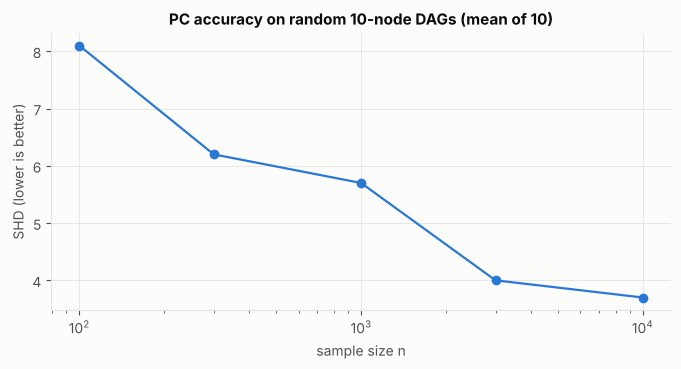

,SHD,true edges
n,,
100,8.1,10.3
300,6.2,10.3
1000,5.7,10.3
3000,4.0,10.3
10000,3.7,10.3


In [5]:
def shd(G_est, A_true):
    k = len(A_true)
    d = 0
    for i in range(k):
        for j in range(i + 1, k):
            est = (G_est[i, j], G_est[j, i])
            tru = (A_true[i, j], A_true[j, i])
            d += est != tru
    return d


rows = []
for n in (100, 300, 1_000, 3_000, 10_000):
    for s in range(10):
        edges = cs.random_dag(n_nodes=10, edge_prob=0.25, seed=s)
        sm_ = cs.linear_gaussian_sem(n=n, edges=edges, seed=100 + s)
        # random_dag may leave isolated nodes out of `nodes`; it's fine: they simply aren't in the data
        G_est = pc_from_scratch(sm_.data.to_numpy(), alpha=0.01)
        rows.append({"n": n, "SHD": shd(G_est, sm_.truth["adjacency"]), "true edges": len(edges)})
acc = pd.DataFrame(rows).groupby("n").mean()

fig, ax = plt.subplots()
ax.plot(acc.index, acc.SHD, marker="o")
ax.set(xscale="log", title="PC accuracy on random 10-node DAGs (mean of 10)", xlabel="sample size n", ylabel="SHD (lower is better)")
plt.show()
acc.round(2)

Part of the remaining SHD is not an error at all: SHD here is measured against the true **DAG**, but PC can only
return the **CPDAG**. Edges that no v-structure or Meek rule can orient stay undirected and count as mistakes.
A fairer score compares against the true CPDAG; computing it is exercise 5.


## 5. Break it: a faithfulness violation

PC assumes every independence in the data comes from the graph structure (**faithfulness**). If two paths cancel
exactly, the data shows an independence the graph does not imply, and PC deletes a real edge.

In [6]:
rng = np.random.default_rng(3)
n = 20_000
A = rng.normal(size=n)
B = 1.0 * A + rng.normal(size=n)
C = 1.0 * B - 1.0 * A + rng.normal(size=n)  # direct A→C exactly cancels A→B→C
Xf = np.column_stack([A, B, C])
print("corr(A, C) =", np.corrcoef(A, C)[0, 1].round(4))
print("PC finds:", edge_list(pc_from_scratch(Xf), ["A", "B", "C"]), "  truth: A → B, B → C, A → C")

corr(A, C) = -0.0019
PC finds: ['A → B', 'C → B']   truth: A → B, B → C, A → C


**What to notice:** PC drops `A → C` and then wrongly declares `A → B ← C` a collider, because `A` and `C` look
independent and `B` is not in their separating set. One cancelling path corrupts both the skeleton and the orientations.

**Exercises**
1. Replace the Fisher-z test with a kernel or rank-based test and generate non-linear data. What breaks when the test is misspecified?
2. Add a hidden common cause of `D` and `F`. PC can't represent it. Read about **FCI** (`causallearn...FCI.fci`), which can.
3. Vary `alpha` (0.001 to 0.2) at n = 300. How do missing vs. extra edges trade off?
4. Run PCMCI (tigramite) on the time series from notebook 08: it is a PC-style algorithm adapted to lagged data.
5. Compute the true CPDAG (apply `orient` to the true skeleton with sepsets derived from d-separation) and re-score SHD against it.